# Individuell uppgift – Hälsostudie, Del 2

Fördjupning med linjär regression, där analyserna samlas i klassen `HealthAnalyzer`.

### Mål
1. Beskriva hur systoliskt blodtryck samvarierar med ålder.
2. Undersöka om blodtryckets samband med rökning ändras när ålder, BMI, kön och kolesterol tas med.

In [1]:
import numpy as np
from health_analyzer import HealthAnalyzer

np.random.seed(42)

analyzer = HealthAnalyzer("data/health_study_dataset.csv")
analyzer.set_plot_style()

### Datakontroll och nya variabler

Datan kontrolleras och tre variabler skapas inför regressionen: `bmi`, `smoker_yes` (1 = rökare, 0 = icke-rökare) och `sex_male` (1 = man, 0 = kvinna).

In [2]:
analyzer.check_data()

analyzer.add_bmi()
analyzer.add_smoker_yes()
analyzer.add_sex_male()

display(analyzer.df[["bmi", "smoker_yes", "sex_male"]].describe().round(2))

bmi = analyzer.df["bmi"]
print(f"Lägsta BMI: {bmi.min():.1f}, högsta BMI: {bmi.max():.1f}")
print(f"Antal deltagare med BMI < 16: {(bmi < 16).sum()}")

Antal rader och kolumner: (800, 9)
Saknade värden: 0
Antal dubbletter av id: 0
Antal dubbletter av rader (exklusive id): 0
Värden i sex: ['F', 'M']
Värden i smoker: ['No', 'Yes']
Värden i disease: [0, 1]


,bmi,smoker_yes,sex_male
count,800.00,800.00,800.0
mean,24.93,0.27,0.5
std,4.66,0.44,0.5
min,12.63,0.00,0.0
25%,21.92,0.00,0.0
50%,24.70,0.00,0.0
75%,28.01,1.00,1.0
max,40.14,1.00,1.0


Lägsta BMI: 12.6, högsta BMI: 40.1
Antal deltagare med BMI < 16: 23


- Inga saknade värden eller dubbletter, och kategorierna är som förväntat.
- BMI spänner från 12,6 till 40,1. BMI under 16 räknas som en extrem gräns för undervikt (källa: https://apps.who.int/nutrition/landscape/help.aspx?menu=0&helpid=392&lang=EN), och de 23 deltagarna under den nivån kan tyda på orealistiska värden. De behålls eftersom inget dokumenterat fel finns, men resultaten tolkas med det i åtanke.

### Analyser från del 1 i klassen

Konfidensintervallet för medelblodtrycket och Welchs t-test är flyttade in i klassen och ger samma resultat som i del 1.

In [3]:
ci_normal = analyzer.confidence_interval_normal()

np.random.seed(42)
ci_bootstrap = analyzer.confidence_interval_bootstrap()

welch = analyzer.welch_test()
t_welch = welch["t"]
p_welch = welch["p_value"]

print(f"95 % CI, normalapproximation: [{ci_normal[0]:.2f}, {ci_normal[1]:.2f}] mmHg")
print(f"95 % CI, bootstrap: [{ci_bootstrap[0]:.2f}, {ci_bootstrap[1]:.2f}] mmHg")
print(f"Welch t-test (ensidigt): t = {t_welch:.2f}, p = {p_welch:.2f}")

95 % CI, normalapproximation: [148.29, 150.07] mmHg
95 % CI, bootstrap: [148.30, 150.07] mmHg
Welch t-test (ensidigt): t = 0.45, p = 0.33


### Enkel linjär regression: blodtryck och ålder

Modellen är ŷ = b₀ + b₁ · ålder, där ŷ är förutsagt systoliskt blodtryck, b₀ är interceptet och b₁ är lutningen (genomsnittlig förändring i mmHg per år). Koefficienterna väljs så att summan av de kvadrerade residualerna (y − ŷ) blir så liten som möjligt. I matrisform är det y = Xb med lösningen b = (XᵀX)⁻¹Xᵀy, vilket också kontrolleras direkt med numpy.

In [4]:
result = analyzer.fit_linear_regression(["age"])

slope = result["coefficients"]["age"]
intercept = result["intercept"]
r2 = result["r2"]

b = analyzer.solve_least_squares(["age"])

print(f"Intercept: {intercept:.2f} mmHg")
print(f"Lutning: {slope:.3f} mmHg per år ({slope * 10:.2f} mmHg per 10 år)")
print(f"R²: {r2:.2f}")
print(f"Kontroll med numpy: intercept = {b[0]:.2f}, lutning = {b[1]:.3f}")

Intercept: 122.68 mmHg
Lutning: 0.536 mmHg per år (5.36 mmHg per 10 år)
R²: 0.37
Kontroll med numpy: intercept = 122.68, lutning = 0.536


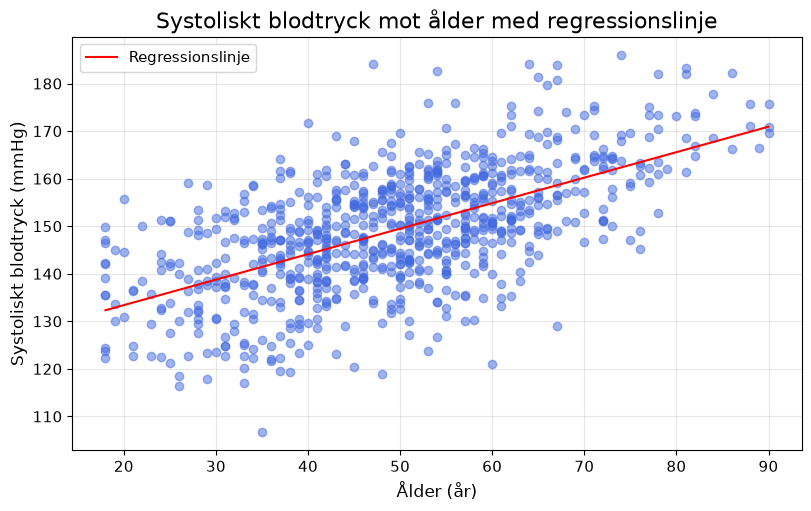

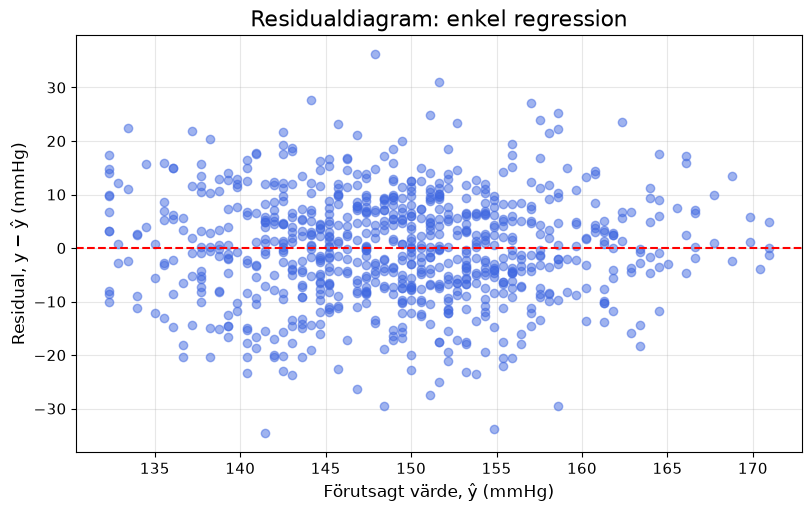

In [5]:
analyzer.plot_fit("age", result)
analyzer.plot_residuals(result, title="Residualdiagram: enkel regression")

- Blodtrycket ökar i genomsnitt med ca 0,54 mmHg per år (ca 5,4 mmHg per 10 år), och ålder förklarar ca 37 % av variationen (R² ≈ 0,37).
- Residualdiagrammet visar ett oregelbundet moln runt noll utan tydligt mönster, vilket tyder på att en rät linje är en rimlig modell.

### Multipel linjär regression

Modellen utökas med BMI, rökning, kön och kolesterol som förklarande variabler. Varje koefficient är den genomsnittliga förändringen i blodtryck (mmHg) när variabeln ökar med en enhet och övriga variabler hålls konstanta (för rökare och man: skillnaden mellan grupperna). Konfidensintervallen beräknas med bootstrap på hela rader (deltagare).

In [6]:
predictors = ["age", "bmi", "smoker_yes", "sex_male", "cholesterol"]
result_multiple = analyzer.fit_linear_regression(predictors)
intercept_multiple = result_multiple["intercept"]
r2_multiple = result_multiple["r2"]

np.random.seed(42)
coefficient_table = analyzer.bootstrap_coefficients(predictors)

print(f"Intercept: {intercept_multiple:.2f} mmHg")
print(f"R²: {r2_multiple:.2f} (enkel regression: {r2:.2f})")
display(coefficient_table.round(2))

Intercept: 111.07 mmHg
R²: 0.40 (enkel regression: 0.37)


,Koefficient,Nedre gräns,Övre gräns
age,0.52,0.47,0.58
bmi,0.34,0.18,0.49
smoker_yes,-0.28,-1.83,1.31
sex_male,2.42,1.08,3.80
cholesterol,0.55,-0.53,1.58


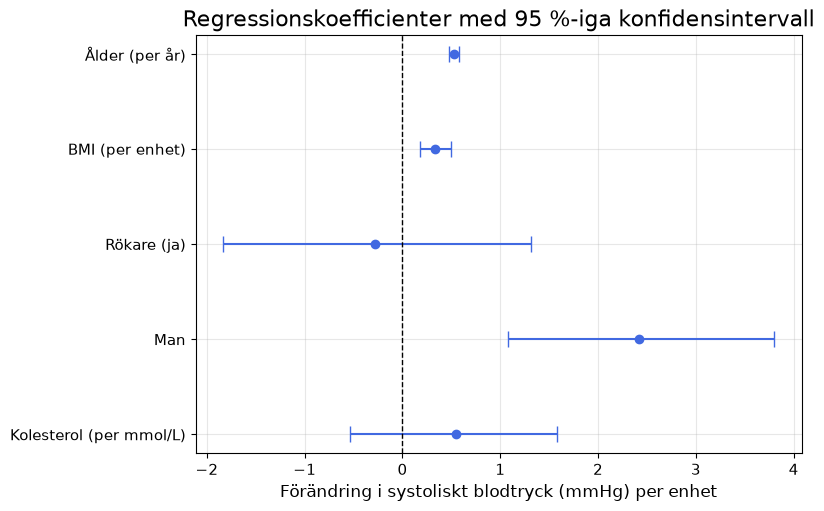

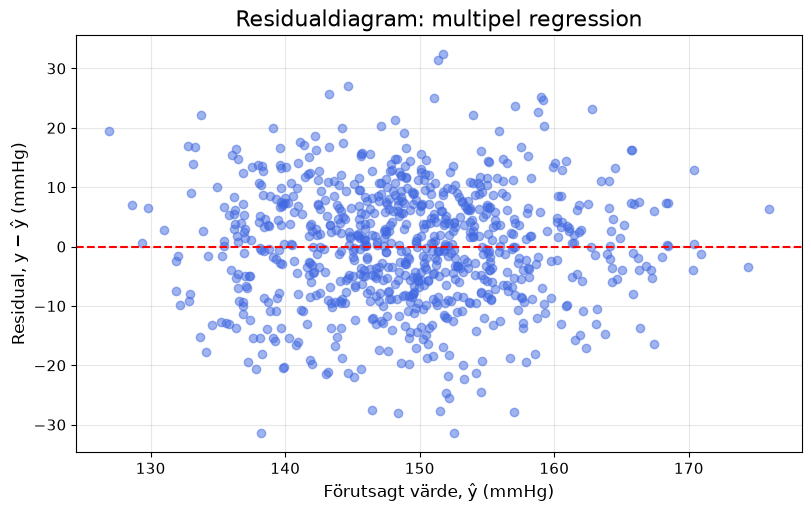

In [7]:
analyzer.plot_coefficients(coefficient_table, labels=["Ålder (per år)", "BMI (per enhet)", "Rökare (ja)", "Man", "Kolesterol (per mmol/L)"])
analyzer.plot_residuals(result_multiple, title="Residualdiagram: multipel regression")

- Efter justering för övriga variabler är koefficienten för rökning ca −0,3 mmHg, med ett intervall (ca −1,8 till +1,3 mmHg) som innehåller 0. Det stämmer med del 1: inga belägg har hittats för att rökare har högre blodtryck, och intervallets övre gräns ligger långt under 5 mmHg.
- Ålder (ca 0,52 mmHg per år), BMI (ca 0,34 mmHg per enhet) och kön (män ca 2,4 mmHg högre än kvinnor) har intervall som ligger helt över noll. Kolesterol har ett intervall (ca −0,5 till +1,6 mmHg per mmol/L) som innehåller 0.
- R² är ca 0,40, så största delen av variationen förklaras inte av modellen. Residualerna ligger oregelbundet utspridda runt noll i residualdiagrammet.
- Resultaten beskriver samband och inte orsakssamband. Modellen är anpassad och utvärderad på samma data, och intervallen är inte justerade för att flera koefficienter granskas samtidigt.

### Motivering av metodval

**Linjär regression.** Systoliskt blodtryck är en kontinuerlig variabel, och linjär regression beskriver hur det samvarierar med en eller flera förklarande variabler. Modellerna anpassades med scikit-learn, och den enkla regressionen kontrollerades med numpy. Den multipla regressionen jämför rökare och icke-rökare efter hänsyn till ålder, BMI, kön och kolesterol.  (Källa: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html och https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html)

**Kodstruktur.** Analyserna samlades i klassen `HealthAnalyzer` i en egen modul, så att koden kan återanvändas och notebooken blir kort. (Källa: https://docs.python.org/3/tutorial/classes.html)

### Sammanfattning

Blodtrycket ökar med ålder, och även med BMI, och män har i genomsnitt högre blodtryck än kvinnor. Kolesterol har inget tydligt samband med blodtryck när övriga variabler tas med. För rökning visar regressionen ingen tydlig skillnad, och skillnaden är liten jämfört med den praktiskt betydelsefulla nivån, vilket stämmer med del 1: inga belägg har hittats för att rökare har högre medelblodtryck. Modellen förklarar bara en del av variationen i blodtryck. Resultaten beskriver samband i ett observationellt dataset och visar inte orsakssamband, och modellen är anpassad och utvärderad på samma data. Ett möjligt nästa steg är att utvärdera modellen på data som inte använts för anpassningen, till exempel med uppdelning i tränings- och testdata.